# Chapter 16: Confidence Intervals and the Pivotal Quantity Method

The computational applications of this chapter of *Theory of Statistics*. The code is generated automatically from the book's `code/ch16/` files; see the book for the explanations and proofs.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/izupress/statistical-theory/blob/main/notebooks/ch_16.ipynb)

$$
\newcommand{\R}{\mathbb{R}}\newcommand{\N}{\mathbb{N}}\newcommand{\E}{\mathbb{E}}
\newcommand{\P}{\mathbb{P}}\newcommand{\F}{\mathcal{F}}\newcommand{\I}{\mathbb{I}}
\newcommand{\Var}{\operatorname{Var}}\newcommand{\Cov}{\operatorname{Cov}}
\newcommand{\Corr}{\operatorname{Corr}}\newcommand{\MSE}{\operatorname{MSE}}
\newcommand{\Bias}{\operatorname{Bias}}\newcommand{\Normal}{\mathcal{N}}
\newcommand{\iid}{\overset{\text{i.i.d.}}{\sim}}\newcommand{\pto}{\xrightarrow{P}}
\newcommand{\dto}{\xrightarrow{d}}\newcommand{\X}{\mathbf{X}}\newcommand{\x}{\mathbf{x}}
$$

In [1]:
# Setup: numpy, scipy and matplotlib are preinstalled on Colab. Locally:
#   pip install -r code/requirements.txt
# Figure files (PDF) saved by the code are written to the _figures/ folder; the figures are
# also shown inside the notebook.
import os
os.makedirs("_figures", exist_ok=True)
os.chdir("_figures")
%matplotlib inline

## Coverage of the $t$ Interval

*Source file:* `code/ch16/c16_1_coverage_of_t_interval.py`

In [2]:
import numpy as np
import scipy.stats as stats

rng = np.random.default_rng(42)
s = rng.normal(50.0, 10.0, size=(100_000, 15))
xb, se = np.mean(s, axis=1), np.std(s, axis=1, ddof=1) / np.sqrt(15)
tc = stats.t.ppf(0.975, df=14)
print(f"Coverage: {np.mean((xb - tc*se <= 50.0) & (50.0 <= xb + tc*se)) * 100:.2f}%")
zc = stats.norm.ppf(0.975)
print(f"with z instead (wrong): {np.mean(np.abs(xb - 50.0) <= zc*se) * 100:.2f}%")

# Departure from normality: the t interval for the mean is robust, the variance interval is not
for name, gen, mu, var in [("Normal", lambda: rng.normal(0, 1, (100_000, 15)), 0, 1),
                          ("Expon.", lambda: rng.exponential(1, (100_000, 15)), 1, 1)]:
    X = gen(); xb = X.mean(1); S2 = X.var(1, ddof=1)
    ct = np.mean(np.abs(xb - mu) <= tc*np.sqrt(S2/15))
    lo, hi = 14*S2/stats.chi2.ppf(0.975, 14), 14*S2/stats.chi2.ppf(0.025, 14)
    cv = np.mean((lo <= var) & (var <= hi))
    print(f"{name} | t-interval coverage={ct:.4f} | chi-square variance interval coverage={cv:.4f}  (target 0.95)")

Coverage: 95.12%
with z instead (wrong): 93.12%
Normal | t-interval coverage=0.9501 | chi-square variance interval coverage=0.9506  (target 0.95)
Expon. | t-interval coverage=0.9118 | chi-square variance interval coverage=0.7430  (target 0.95)


## Binomial Proportion: Wald, Wilson, Clopper–Pearson, Agresti–Coull

The coverage probabilities were computed exactly (by weighting with binomial probabilities).

*Source file:* `code/ch16/c16_2_binomial_wald_wilson_clopper_pearson.py`

n= 30 Wald             | mean coverage=0.8822 | min coverage=0.1396
n= 30 Wilson           | mean coverage=0.9527 | min coverage=0.8604
n= 30 Clopper-Pearson  | mean coverage=0.9731 | min coverage=0.9537
n= 30 Agresti-Coull    | mean coverage=0.9598 | min coverage=0.9339


n=100 Wald             | mean coverage=0.9288 | min coverage=0.3941
n=100 Wilson           | mean coverage=0.9511 | min coverage=0.9102
n=100 Clopper-Pearson  | mean coverage=0.9642 | min coverage=0.9504
n=100 Agresti-Coull    | mean coverage=0.9552 | min coverage=0.9391


n=100, p=0.01 | Wald=0.6334 | Wilson=0.9206 | CP=0.9816
n=100, p=0.05 | Wald=0.8775 | Wilson=0.9659 | CP=0.9826
n=100, p=0.20 | Wald=0.9331 | Wilson=0.9405 | CP=0.9674
n=100, p=0.50 | Wald=0.9431 | Wilson=0.9431 | CP=0.9648


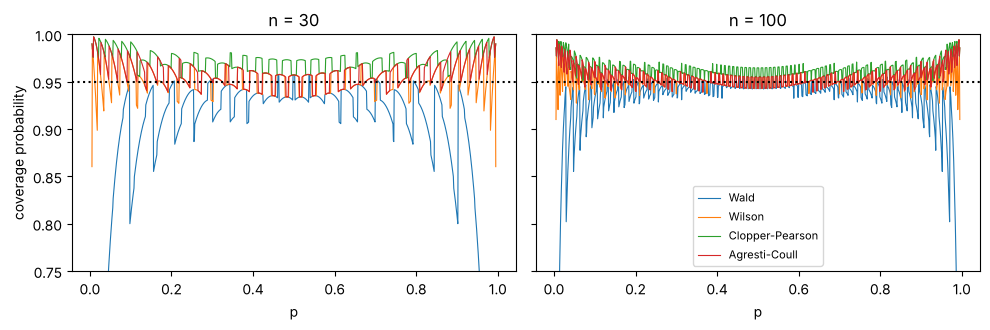

In [3]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

def intervals(x, n, a=0.05):
    z = stats.norm.ppf(1 - a/2); p = x / n
    wald = (p - z*np.sqrt(p*(1-p)/n), p + z*np.sqrt(p*(1-p)/n))
    m = (p + z**2/(2*n)) / (1 + z**2/n); h = z/(1 + z**2/n)*np.sqrt(p*(1-p)/n + z**2/(4*n**2))
    wilson = (m - h, m + h)
    cp = (np.nan_to_num(stats.beta.ppf(a/2, x, n - x + 1), nan=0.0),
          np.nan_to_num(stats.beta.ppf(1 - a/2, x + 1, n - x), nan=1.0))
    nt = n + z**2; pt = (x + z**2/2)/nt
    ac = (pt - z*np.sqrt(pt*(1-pt)/nt), pt + z*np.sqrt(pt*(1-pt)/nt))
    return {"Wald": wald, "Wilson": wilson, "Clopper-Pearson": cp, "Agresti-Coull": ac}

def coverage(n, ps):
    x = np.arange(n + 1); A = intervals(x, n)
    return {k: np.array([np.sum(stats.binom.pmf(x, n, p) * ((L <= p) & (p <= U))) for p in ps])
            for k, (L, U) in A.items()}

ps = np.linspace(0.005, 0.995, 991)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, n in zip(axes, [30, 100]):
    K = coverage(n, ps)
    for k, v in K.items():
        ax.plot(ps, v, lw=0.8, label=k)
        print(f"n={n:3d} {k:16s} | mean coverage={v.mean():.4f} | min coverage={v.min():.4f}")
    ax.axhline(0.95, color="k", ls=":"); ax.set_ylim(0.75, 1.0); ax.set_xlabel("p"); ax.set_title(f"n = {n}")
axes[0].set_ylabel("coverage probability"); axes[1].legend(fontsize=8, loc="lower center")
fig.tight_layout(); fig.savefig("binom_kapsama.pdf")
for p in [0.01, 0.05, 0.2, 0.5]:
    K = coverage(100, [p])
    print(f"n=100, p={p:.2f} | Wald={K['Wald'][0]:.4f} | Wilson={K['Wilson'][0]:.4f} | CP={K['Clopper-Pearson'][0]:.4f}")

## The Pivotal Interval for $\text{Uniform}(0,\theta)$

*Source file:* `code/ch16/c16_3_uniform_pivotal_interval.py`

In [4]:
import numpy as np

rng = np.random.default_rng(42)
theta, a, R = 7.0, 0.05, 200_000
for n in [5, 20, 100]:
    M = rng.uniform(0, theta, size=(R, n)).max(axis=1)
    L, U = M, M * a**(-1/n)
    print(f"n={n:3d} | coverage={np.mean((L <= theta) & (theta <= U)):.4f} | mean length={np.mean(U - L):.4f}"
          f" | theory={theta*n/(n+1)*(a**(-1/n) - 1):.4f}")

n=  5 | coverage=0.9502 | mean length=4.7865 | theory=4.7866
n= 20 | coverage=0.9495 | mean length=1.0773 | theory=1.0772


n=100 | coverage=0.9500 | mean length=0.2108 | theory=0.2108
